In [3]:
# !pip install torch==2.10.0 torchvision==0.25.0 torchaudio==2.10.0 torchmetrics==1.9.0
# !pip install numpy==2.2.6

# Deep Learning Lab 03: Introduction to Computer Vision

In [2]:
import os
from math import sqrt
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt
import numpy as np
from IPython.display import YouTubeVideo, display

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchmetrics import Accuracy, MeanMetric

from torchvision.datasets import MNIST
from torchvision.transforms import Compose, Resize, ToTensor, RandomAffine
from torchvision.utils import make_grid


## 1. Introduction

During this lab session, we will study the very recent and well-known deep learning architecture for computer vision called **Vision Transformer** or in short **ViT**.


The transformer architecture, introducing the idea of self-attention, has revolutionized the field of Natural Language Processing (NLP). Its usage is now common for solving many different NLP tasks. It was only a matter of time for this architecture to be adapted for the Computer Vision field. It is finally at ICLR 2021, that Dosovitskiy et Al. introduced in their paper: [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929) a Transformer architecture designed for Computer Vision tasks: **The Vision Transformer** or **ViT**.

<img src="images/vit.png" alt="Tokenization + Embedding" height="300" width="500"/>

Specifically, the goal of this lab is to:
1. Implement from scratch the whole ViT architecture.
2. Train the implemented architecture on the MNIST dataset.
3. Visualize attention maps from the trained ViT.

## 2. ViT Implementation

### 2.1 Tokenization + Embedding

<img src="images/tokenization+embedding.png" alt="Tokenization + Embedding" height="300" width="500"/>

In transformer architecture, the first steps are usally **Tokenization** and **Embedding**.

- **Tokenization** consists in splitting the raw input data into individual tokens. For example, considering a sentence, it can be splitted into individual words (word-based tokenization), groups of characters (subword-based tokenization), individual characters (charachter-based tokenization). In the ViT architecture, the **tokenization** step splits the image into a 1D sequence of flattened patches.

- **Embedding** consists in projecting each individual token into a lower dimensional space. In the ViT architecture, the **Embedding** projects each flattened patch into a lower dimensional space.

#### 2.1.1 Implementation

In the ViT architecture, the **tokenization** + **embedding** steps can be done efficiently using a 2D convolution.

Given a RGB image with dimensions $128 \times 128 \times 3$, patches with dimensions $16 \times 16$ and $D$ the dimension of the embedding space, what (kernel sizes, strides, number of output channels) would you set for the 2D convolution to obtain the embedding of the flattened patches with dimension $128 / 16 \times 128 / 16 \times D = 8 \times 8 \times D$ ?

>

Now, fill the `PatchEmbedding` class supposed to implement **tokenization** and **embedding** of an image

In [22]:
class PatchEmbedding(nn.Module):

    def __init__(self, img_size, patch_size, input_channels, output_channels):
        """Constructor of PatchEmbedding module

        Args:
            img_size (tuple): 2D tuple specifying the image dimensions (H, W)
            patch_size (tuple): 2D tuple specifying the patch dimensions (p_h, p_w)
            input_channels (int): Number of channels of the input image
            output_channels (int): Number of output channels of the 2D
                convolution  / Dimension of the patch embeddings.
        """
        super().__init__()
        self.output_channels = output_channels
        h, w = img_size
        patch_h, patch_w = patch_size
        # Make sure that img size is divisible per patch_size
        assert h % patch_h == 0 and w % patch_w == 0, "img size must be divisible per patch_size"

        # Initializing the 2D convolution used for tokenization + embedding steps
        ########### To complete
        self.patch_emb = nn.Conv2d(
            in_channels=input_channels,
            out_channels=output_channels,
            kernel_size=patch_size,
            stride=patch_size)
        ###########
        self.num_patches = h // patch_h * w // patch_w

    def forward(self, x):
        """Forward pass of PatchEmbedding module

        Args:
            x (torch.Tensor): Batch of images with shape
                (batch_size, input_channels, H, W)

        Returns:
            torch.Tensor: Embbeded patches with shape
                (batch_size, num_patches, output_channels)
        """

        ########### To complete
        # Embed patch using the 2D convolution
        tokens = self.patch_emb(x)

        # Flatten spatial dimension to go from (batch_size, out_channels, patch_h, patch_w)
        # to (batch_size, out_channels, num_patch_h * num_patch_w)
        tokens = tokens.reshape([x.size(0), self.output_channels, -1])

        # Permute second and third axis so that patch features dimension is the last one
        # i.e (batch_size, num_patch_h * num_patch_w, out_channels)
        tokens = tokens.swapaxes(1, 2)
        ###########
        return tokens

#### 2.1.2 Sanity check

In [23]:
# Define random images
batch_size = 1
input_channels = 3
img_size = (128, 128)
images = torch.randn(batch_size, input_channels, *img_size)
print(f'images: {images.shape}')

# Apply tokenization + embedding
embedding_dim = 256
patch_emb = PatchEmbedding(
    img_size=img_size,
    patch_size=(16, 16),
    input_channels=input_channels,
    output_channels=embedding_dim)
embedded_patches = patch_emb(images)

assert tuple(embedded_patches.shape) == (batch_size, patch_emb.num_patches, 256),\
    f'Computed embedded shape {tuple(embedded_patches.shape)} does not match the expected shape {(batch_size, patch_emb.num_patches, embedding_dim)}'

print(f'embedded_patches: {embedded_patches.shape}')

images: torch.Size([1, 3, 128, 128])
embedded_patches: torch.Size([1, 64, 256])


### 2.2 Positional embeddings + Class token

<img src="images/class_token+positional_embeddings.png" alt="Class token + Positional embeddings" height="300" width="500"/>

- <u>**Positional embeddings**</u>

In transformer architectures, without positional embeddings, the network would have not any clue of the ordering of the tokens in the sequence. While, this information can be crucial and can completely change the semantics of sequence. As example, in a transformer for NLP without position embeddings, the words sequences `('Tom', 'bit', 'a', 'dog')` and `('A', 'dog', 'bit', 'Tom')` would results in similar semantics.
Therefore the role of **Positional embeddings/encodings** is to associate to each token position a unique vector in order to inject into the network the tokens positions information.
There exists different methods to create **positional embeddings** (fixed, learnable, ...). In our ViT implementation, we will used learnable **positional embeddings** initialized randomly with standard gaussian distribution.

- <u>**Class tokens**</u>  

Usually in transformer, a learnable **class token** with the same dimension as other tokens is prepended to the sequence of tokens. Throughout the whole transformer encoder, thanks to self-attention, the **class token** gathers information from all other tokens. Finally the output representation of the class token is fed to the **MLP head**.

#### 2.2.1 Implementation

Fill the code of the following classes `AddPositionalEmbeddings` and `PrependClassToken`

In [24]:
class AddPositionalEmbeddings(nn.Module):

    def __init__(self, num_tokens, patch_emb_dim):
        """Constructor of AddPositionalEmbeddings module

        Args:
            num_tokens (int): Number of tokens
            patch_emb_dim (int): Dimension of patch embeddings
        """

        super().__init__()
        # Define learnable positional encodings that will be added to
        # tokens.
        ########### To complete
        self.pos_emb = nn.Parameter(
            torch.randn(1, num_tokens, patch_emb_dim))
        ###########

    def forward(self, tokens):
        """Forward pass of AddPositionalEmbeddings module that should add the
        positional embeddings to the tokens.

        Args:
            tokens (torch.Tensor): Tokens with shape
                (batch_size, num_tokens, patch_emb_dim)

        Returns:
            torch.Tensor: Tokens with positional embeddings and shape
                (batch_size, num_tokens, patch_emb_dim).
        """
        # Add positional embeddings
        ########### To complete
        tokens = tokens + self.pos_emb
        ###########
        return tokens
        

In [25]:
class PrependClassToken(nn.Module):

    def __init__(self, patch_emb_dim):
        """Constructor of PrependClassToken module

        Args:
            patch_emb_dim (int): Dimension of patch embeddings
        """

        super().__init__()
        # Define class token with same dimension as patch embeddings
        ########### To complete
        self.cls_token = nn.Parameter(
            torch.randn(patch_emb_dim))
        ###########

    def forward(self, tokens):
        """Forward pass of PrependClassToken module that should prepend the
        class token to the tokens.

        Args:
            tokens (torch.Tensor): Tokens with shape
            (batch_size, num_patches, patch_emb_dim)

        Returns:
            torch.Tensor: Concatenated class token and tokens with
            shape (batch_size, 1+num_patches, patch_emb_dim).
        """
        ########### To complete
        # Add 2 additional axis to class token to have the same number of dims
        # than tokens
        cls_token = self.cls_token[None, None, ...]

        # Repeat batch_size times the class token along batch axis
        batch_size = tokens.size(0)
        cls_token = cls_token.repeat([batch_size, 1, 1])

        # Prepend class tokens to tokens
        tokens = torch.cat([cls_token, tokens], dim=1)
        ###########
        return tokens

### 2.3 Transformer encoder + Transfomer block

<img src="images/transformer_encoder.png" alt="Transformer encoder" height="300" width="500"/>

As described in the picture above, **Transformer encoder** is made of $L$ stacked **transformer blocks**.
Each **transformer block** is made of the following operations:
1. Layer Normalization
2. Multi-head attention
3. Concatenatation of Multi head attention representations + Residual connection
4. Layer Normalization + Multilayer Perceptron + Residual connection
5. MLP with 2 hidden layers with same input and output dimensions.

The **Multi-head attention** is the most crucial component of the Transformer architecture as it allows interactions between all the different tokens and is the main reason behind the Transformer success.
We describe in the following figure how a single-head self-attention works internally as multi-head self-attention derives naturally by concatenating the outputs produced by several single-head self-attention in parallel:

<img src="images/single_head_self_attention.png" alt="Single-head self-attention" height="300" width="600"/>

1. Given a sequence of tokens with representations $Z = \{z_t\}_{\{1 \leq t \leq T\}}$, the tokens are linearly projected using weights matrices $W_Q$, $W_K$, $W_V$ to obtain respectively the sets of queries $Q = \{q_t\}_{\{1 \leq t \leq T\}}$, keys $K = \{k_t\}_{\{1 \leq t \leq T\}}$ and values $V = \{v_t\}_{\{1 \leq t \leq T\}}$.
2. Similarities between queries and keys are computed, rescaled and normalized (**Attention maps**):
\begin{equation*}
A = softmax\left( \frac{{Q}{K}
^T}{\sqrt{d_k}}\right)
\end{equation*}
3. Values are linearly combined according similiraties between queries and keys to produce the output sequence of tokens $Z' = \{z'_t\}_{\{1 \leq t \leq T\}}$:
\begin{equation*}
{Z'} = AV
\end{equation*}
4. Finally, the output sequence of tokens $Z'$ is linearly projected into the output sequence $Z'' = \{z''_t\}_{\{1 \leq t \leq T\}}$.

#### 2.3.1 Implementation


Fill the code of the following classes `MultiHeadSelfAttention` and `TransformerBlock`. The code of the class `MLPHead` is already provided.

In [26]:
class MultiHeadSelfAttention(nn.Module):

    """Class implementing the multi-head self-attention

    Attributes:
        dim_head (int): Query, key, value dimension for single-head
        heads (int): Number of heads
        to_qkv (nn.Linear): Fully connected layer projecting a token into all
            (queries, keys, values) for all heads. So the output dimension is
            3 * heads * dim_head.
        to_out (nn.Linear): Fully connected layer projecting Z' into Z''
    """

    def __init__(self, in_token_dim, dim_head, heads):
        """Constructor of the MultiHeadSelfAttention Module

        Args:
            in_token_dim (int): Input tokens dimension
            dim_head (int): Query, key, value dimension for single-head
            heads (int): Number of heads
        """
        super().__init__()
        self.dim_head = dim_head
        self.heads = heads
        ########### To complete
        out_dim = heads * dim_head
        self.to_qkv = nn.Linear(in_token_dim, 3 * out_dim)
        self.to_out = nn.Linear(out_dim, in_token_dim)
        ###########

    def forward(self, tokens):
        """Forward pass of the MultiHeadSelfAttention Module

        Args:
            tokens (torch.Tensor): Tokens with shape
                (batch_size, num_patches, in_token_dim)

        Returns:
            tuple: (
                Output tokens with shape (batch_size, num_tokens, in_token_dim),
                Attention maps with shape (batch_size, heads, num_tokens, num_tokens)
                )
        """
        ########### To complete
        # Computes queries, keys and values for all heads
        # (batch_size, tokens, 3 * heads * dim_head)
        qkv = self.to_qkv(tokens)
        # Split qkv into queries, keys and values
        q, k, v = qkv.chunk(3, dim=-1)

        # Reshape queries, keys and values (batch_size, tokens, heads * dim_head) into
        # (batch_size, tokens, dim_head, heads)
        bs, num_tokens = q.shape[:-1]
        q = q.reshape([bs, num_tokens, self.heads, self.dim_head])
        k = k.reshape([bs, num_tokens, self.heads, self.dim_head])
        v = v.reshape([bs, num_tokens, self.heads, self.dim_head])

        # Permute axes of Q and K so that axes are (batch_size, heads, tokens, dim_head)
        q = q.permute(0, 2, 1, 3)
        k = k.permute(0, 2, 3, 1)

        # Computes attention matrix per head (batch_size, heads, tokens, tokens)
        atts = q @ k
        # Divide attention by scale (1 / sqrt(dim_head))
        atts = atts/sqrt(self.dim_head)
        # Normalize attention with softmax
        atts = atts.softmax(dim=-1)

        # Reshape attentions into (batch_size, heads, tokens, dim_head)
        v = v.permute(0, 2, 1, 3)
        # Multiply values by attentions
        # (batch_size, heads, tokens, tokens) @ (batch_size, heads, tokens, dim_head)
        out = atts @ v
        # Concatenate head representations. Output tensor must have (batch_size, tokens, heads * dim_head)
        out = out.permute(0, 2, 1, 3).flatten(start_dim=2)

        # Project output
        out = self.to_out(out)
        ###########

        return out, atts

In [27]:
class MLP(nn.Module):

    def __init__(self, in_dim, hidden_dim, out_dim):
        """Constructor of MLP module used in the multi-head self-attention

        Args:
            in_dim (int): Dimension of input tokens
            hidden_dim (int): Hidden dimension of MLP
            out_dim (int): Dimension of output tokens
        """
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, out_dim),
        )
    def forward(self, tokens):
        """Forward pass of the MLP

        Args:
            tokens (torch.Tensor): Input tokens with shape
                (batch_size, in_dim, num_tokens)

        Returns:
            torch.Tensor: Ouput tokens with shape
                (batch_size, out_dim, num_tokens)
        """
        return self.net(tokens)

In [28]:
class TransformerBlock(nn.Module):

    def __init__(self, in_dim, dim_head, heads, mlp_hid_dim):
        """Constructor of TransformerBlock module

        Args:
            in_dim (int): Dimension of input tokens
            dim_head (int): Dimension of the query, key and value produced by a single-head
                self-attention
            heads (int): Number of heads to run in parallel
            mlp_hid_dim (int): Hidden dimension of MLP
        """
        super().__init__()
        ########### To complete
        self.ln1 = nn.LayerNorm(in_dim)
        self.multi_head_self_att = MultiHeadSelfAttention(
            in_dim, dim_head, heads)
        self.ln2 = nn.LayerNorm(in_dim)
        self.mlp = MLP(in_dim, mlp_hid_dim, in_dim)
        ###########

    def forward(self, tokens):
        """Forward pass of the TransformerBlock

        Args:
            tokens (torch.Tensor): Input tokens with shape
                (batch_size, in_dim, num_tokens)

        Returns:
            tuple: (
                Output tokens with shape (batch_size, num_tokens, in_dim),
                Attention maps with shape (batch_size, heads, num_tokens, num_tokens)
                )
        """
        ########### To complete
        # Apply layer norm + multi head self attention
        out, atts = self.multi_head_self_att(self.ln1(tokens))
        # Apply residual connection
        out = out + tokens
        # Apply layer norm + MLP + residual connection
        out = self.mlp(self.ln2(out)) + out
        ###########
        return out, atts

### 2.4 MLP head

<img src="images/MLP.png" alt="MLP head" height="300" width="500"/>

In the **ViT** architecture, the final output of the network is produced by feeding the output representation of the **class token** to the **MLP head**. The **MLP head** is just a simple fully connected layer. Fill the class `MLPHead` that implments the **MLP Head**.

In [29]:
class MLPHead(nn.Module):

    def __init__(self, in_dim, num_classes):
        """Constructor of MLPHead module

        Args:
            in_dim (int): Dimension of the class token output
                representation
            num_classes (int): Number of classes to predict
        """
        super().__init__()
        ########### To complete
        self.fc = nn.Linear(in_dim, num_classes)
        ###########

    def forward(self, cls_token):
        """Forward pass of the MLPHead

        Args:
            cls_token (torch.Tensor): Class tokens output representations with
                shape (batch_size, in_dim)

        Returns:
            torch.Tensor: Classes logits with shape (batch_size, num_classes)
        """
        ########### To complete
        return self.fc(cls_token)
        ###########

### 2.5 The whole ViT

#### 2.5.1 Implementation

Fill the code of the class `ViT`. Make sure to add a LayerNorm on the output of transformer encoder before feeding representations to the **MLP head**.

In [30]:
class ViT(nn.Module):

    """Class implementing the ViT architecture
    """

    def __init__(self,
                 img_size,
                 patch_size,
                 input_channels,
                 patch_emb_dim,
                 depth,
                 heads,
                 mlp_hid_dim,
                 num_classes):
        """Constructor of ViT module

        Args:
            img_size (tuple): Image size (H, W)
            patch_size (tuple): Path size (p_h, p_w)
            input_channels (int): Number of channels of input images
            patch_emb_dim (int): Dimension of the patch embedding
            depth (int): Number of transformer blocks
            heads (int): Number of head for each transformer block
            mlp_hid_dim (int): Hidden layer dimension in the MLP
            num_classes (int): Number of classes to predict
        """
        super().__init__()

        ########### To complete
        # Define patch embedding
        self.patch_embedding = PatchEmbedding(
            img_size=img_size,
            patch_size=patch_size,
            input_channels=input_channels,
            output_channels=patch_emb_dim,)

        # Define prepend class token module
        self.prepend_cls_token = PrependClassToken(patch_emb_dim)

        # Define add positional embeddings module (position embeddings will
        # be added to cls_tokens and other tokens)
        self.add_pos_emb = AddPositionalEmbeddings(
            num_tokens=self.patch_embedding.num_patches + 1,
            patch_emb_dim=patch_emb_dim)


        # Define consecutive transformer blocks
        self.transformer_encoder = nn.ModuleList([TransformerBlock(
            in_dim=patch_emb_dim,
            dim_head=patch_emb_dim//heads,
            heads=heads,
            mlp_hid_dim=mlp_hid_dim) for _ in range(depth)])

        # Define last layer norm
        self.norm_layer = nn.LayerNorm(patch_emb_dim)

        # Define mlp head
        self.mlp_head = MLPHead(
            in_dim=patch_emb_dim,
            num_classes=num_classes)
        ###########

    def forward(self, x):
        """Forward pass of the ViT

        Args:
            x (torch.Tensor): Images with shape
                (batch_size, input_channels, H, W)

        Returns:
            tuple: (
                Output logits eith shape (batch_size, num_classes),
                Output tokens with shape (batch_size, num_tokens, patch_emb_dim),
                List of attention maps for each transformer block.
                    Each element of the list (attention maps) has shape
                    (batch_size, heads, num_tokens, num_tokens)
                )
        """
        ########### To complete
        # Embed the patch + flatten spatial dimensions and swap axes to get
        # tokens
        tokens = self.patch_embedding(x)

        # Preprend class tokens to other tokens
        tokens = self.prepend_cls_token(tokens)

        # Add positional embeddings to all tokens
        tokens = self.add_pos_emb(tokens)

        # Apply consecutive transformer block
        attentions = []
        for transformer_block in self.transformer_encoder:
            tokens, atts = transformer_block(tokens)
            attentions.append(atts)

        # Apply last layer norm
        tokens = self.norm_layer(tokens)

        # Get class token output representation
        cls_tokens = tokens[:, 0]
        # Feed class token output representation to mlp head
        pred = self.mlp_head(cls_tokens)
        ###########
        return pred, tokens, attentions


#### 2.5.2 Sanity check

In [31]:
# Define hyperparameters
batch_size = 2
img_size = (32, 32)
patch_size = (4, 4)
input_channels = 3
patch_emb_dim = 16
depth = 3
heads = 4
mlp_hid_dim = 8
num_classes = 10

# Define ViT
vit = ViT(
    img_size=img_size,
    patch_size=patch_size,
    input_channels=input_channels,
    patch_emb_dim=patch_emb_dim,
    depth=depth,
    heads=heads,
    mlp_hid_dim=mlp_hid_dim,
    num_classes=10)

# Get predictions + display dimensions
x = torch.randn(batch_size, input_channels, *img_size)
pred, out, atts = vit(x)
print(f'pred: {pred.shape}')
print(f'out: {out.shape}')
print(f'atts: {[a.shape for a in atts]}')

pred: torch.Size([2, 10])
out: torch.Size([2, 65, 16])
atts: [torch.Size([2, 4, 65, 65]), torch.Size([2, 4, 65, 65]), torch.Size([2, 4, 65, 65])]


## 3. Train ViT on MNIST

### 3.1 Hyperparameters definition

In [32]:
# Define ViT hyperparameters
img_size = (32, 32)
patch_size = (4, 4)
input_channels = 1
patch_emb_dim = 32
depth = 4
heads = 8
mlp_hid_dim = 32
num_classes = 10

# Define optimization hyperparameters
batch_size = 64
lr = 1e-3
epochs = 600
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

### 3.2 Data, networks and optimizer definitions

In [33]:
# Initialize data transformation for train and test
train_transform = Compose([
    ToTensor(),
    Resize(img_size),
    RandomAffine(degrees=0, translate=[0.05, 0.05])
])
test_transform = Compose([
    ToTensor(),
    Resize(img_size),
])


# Create train and test pytorch datasets
train_dataset = MNIST(root='.', train=True, download=True, transform=train_transform)
test_dataset = MNIST(root='.', train=False, download=True, transform=test_transform)

# Create train and test dataloaders
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
    num_workers=10)
test_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=False,
    drop_last=False,
    num_workers=10)

# Create ViT
vit = ViT(
    img_size=img_size,
    patch_size=patch_size,
    input_channels=input_channels,
    patch_emb_dim=patch_emb_dim,
    depth=depth,
    heads=heads,
    mlp_hid_dim=mlp_hid_dim,
    num_classes=num_classes).to(device)

# Define optimizer
optimizer = Adam(params=vit.parameters(), lr=lr)

# Define cosine decay learning rate scheduler
lr_scheduler = CosineAnnealingLR(
    optimizer=optimizer,
    T_max=epochs)

### 3.3 Training

In [34]:
# Create torchmetrics metrics to keep track of loss and accuracy during training
mean_loss = MeanMetric().to(device)
train_acc = Accuracy(task='multiclass', num_classes=num_classes).to(device)

for epoch in range(1, epochs+1):

    # Create tqdm progress bar to display epoch progress and metrics
    pbar = tqdm(train_dataloader, unit='batches')
    for X, y in pbar:
        # Zero-out gradients of optimizer
        optimizer.zero_grad()

        # Move data to appropriate device
        X = X.to(device)
        y = y.to(device)

        # Make predictions
        y_pred, *_ = vit(X)
        loss = F.cross_entropy(input=y_pred, target=y)

        # Compute loss gradients with respect to parameters
        loss.backward()
        mean_loss.update(loss)
        train_acc.update(y_pred, y)

        pbar.set_description(
            'Epoch {}/{}: Loss: {:.3f}, Acc: {:.3f}, lr: {:.5f}'.format(
                epoch,
                epochs,
                mean_loss.compute().item(),
                train_acc.compute().item() * 100,
                lr_scheduler.get_last_lr()[0]))

        # Update parameters
        optimizer.step()

    # Update learning rate
    lr_scheduler.step()

    # Reset average metrics for next epoch
    mean_loss.reset()
    train_acc.reset()

  0%|          | 0/937 [00:00<?, ?batches/s]

  0%|          | 0/937 [00:00<?, ?batches/s]

  0%|          | 0/937 [00:00<?, ?batches/s]

  0%|          | 0/937 [00:00<?, ?batches/s]

  0%|          | 0/937 [00:00<?, ?batches/s]

  0%|          | 0/937 [00:00<?, ?batches/s]

... (590 outputs left out)

  0%|          | 0/937 [00:00<?, ?batches/s]

  0%|          | 0/937 [00:00<?, ?batches/s]

  0%|          | 0/937 [00:00<?, ?batches/s]

  0%|          | 0/937 [00:00<?, ?batches/s]

### 3.4 Evaluation

In [35]:
# Change model mode train --> eval
vit = vit.eval()

# make sure that no intermediate values in the network
# are stored for gradients computation
test_acc = Accuracy(task='multiclass', num_classes=num_classes).to(device)
with torch.no_grad():

    preds = []
    targets = []
    for X, y in tqdm(test_dataloader):

        # Zero-out gradients of optimizer
        optimizer.zero_grad()

        # Move data to appropriate device
        X = X.to(device)
        y = y.to(device)

        # Make predictions
        y_pred, tokens, atts = vit(X)

        # Update acc metric
        test_acc.update(y_pred, y)

print(f'Test accuracy: {test_acc.compute()}')

  0%|          | 0/938 [00:00<?, ?it/s]

Test accuracy: 0.9997166395187378


## 4. Visualize attention maps

`Vit` attention maps provide an useful tool for explainability. Indeed, given a specific transformer block and attention head, one can retrieve the attention map associated to the similarity between the class token (query) and all other tokens except the class token (keys). These attention maps give you an information about what part of the image is responsible for the network prediction.

Fill the function `visualize_att_maps` to plot, for each transformer block, these attention maps averaged over the different heads

In [36]:
def visualize_att_maps(X, atts, num_images_to_plot=16):
    """Plots grid of attention maps for each transformer block

    Args:
        X (torch.Tensor): Images tensor with shape
            (batch_size, num_channels, H, W)
        atts (list[torch.Tensor]): List of transformer block attention maps.
            Each of them has a shape (batch_size, num_heads, num_tokens, num_tokens)
        num_images_to_plot (int, optional): Number of attention maps
            to display in the grid
    """
    # Retrieve only num_images_to_plot
    images = X[:num_images_to_plot]
    atts = [a[:num_images_to_plot] for a in atts]

    # Loop over attention maps of each transformer block
    for transformer_block_index, att_maps in enumerate(atts, start=1):

        ########### To complete
        # Get attention maps where query is class token and keys are all other tokens.
        att_maps = att_maps[:, :, 0, 1:]
        bs, num_heads, num_tokens = att_maps.shape

        # Get number of patches along height, width
        patch_h = patch_w = int(sqrt(num_tokens))

        # Reshape attention maps into grid
        # (batch_size, num_heads, num_patches_H,num_patches_W)
        att_maps = att_maps.view(bs, num_heads, patch_h, patch_w)


        # Average attention maps along attention-head axis.
        att_maps = att_maps.mean(dim=1, keepdim=True)
        # Interpolate averaged attention maps to the same size as images.
        att_maps = F.interpolate(att_maps, size=img_size, mode='bilinear')

        # Rescale attention maps values between [0, 1]
        mini = att_maps.min(
            dim=-2, keepdim=True)[0].min(dim=-1, keepdim=True)[0]
        maxi = att_maps.max(
            dim=-2, keepdim=True)[0].max(dim=-1, keepdim=True)[0]
        att_maps = (att_maps - mini) / (maxi - mini)
        ###########

        # Create grid of images and attention maps. Images and attention maps
        # must have a shape (num_images_to_plot, 1, H, W).
        images_grid = make_grid(images, nrow=int(
            sqrt(bs))).cpu().permute(1, 2, 0).numpy()
        atts_grid = make_grid(att_maps, nrow=int(
            sqrt(bs))).cpu().permute(1, 2, 0).numpy()

        # Create matplotlib figure and display grids
        fig, axes = plt.subplots(1, 2, figsize=(8, 8))
        axes[0].imshow(images_grid)
        axes[1].imshow(atts_grid)
        fig.suptitle(f'Grid of attention maps for transformer_block {transformer_block_index}')
        fig.tight_layout()
        plt.show()

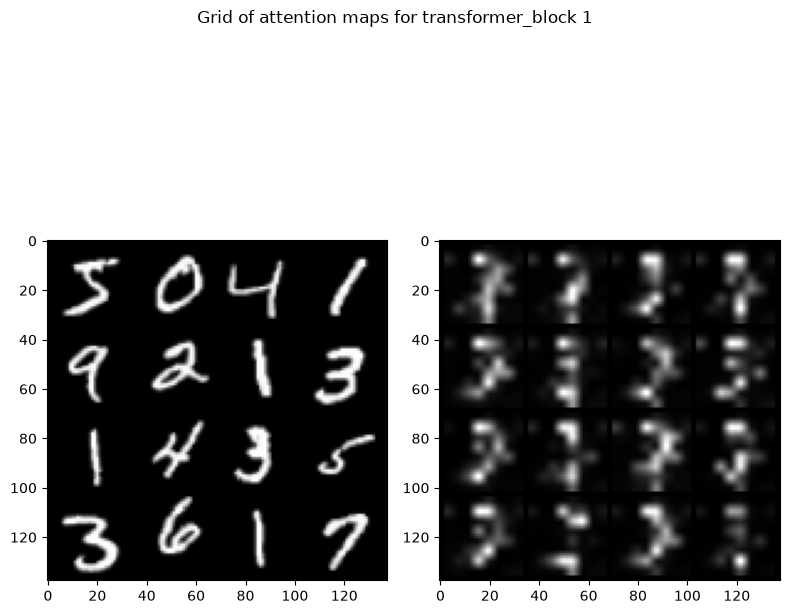

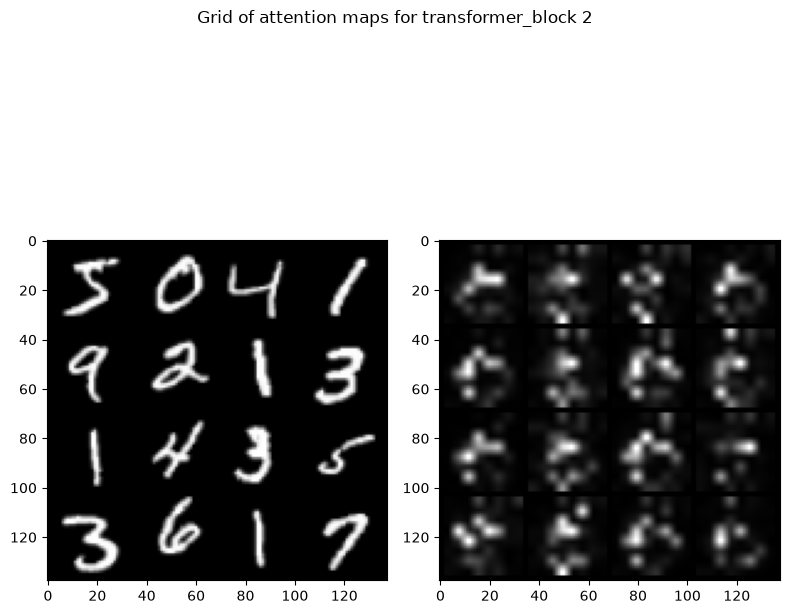

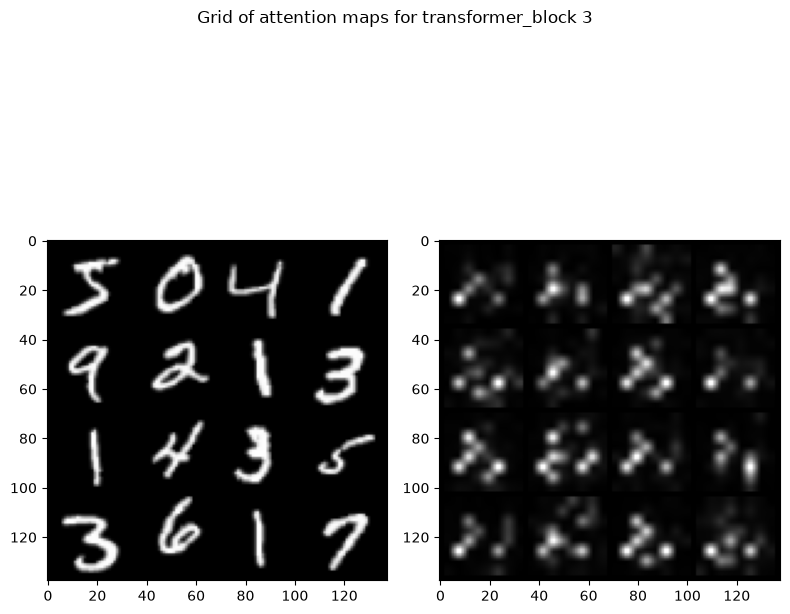

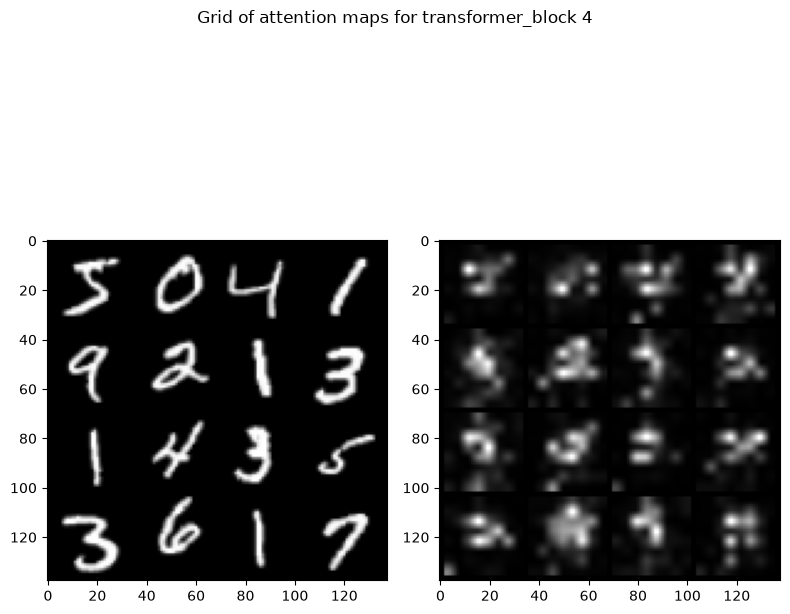

In [37]:
X, _ = next(iter(test_dataloader))
with torch.no_grad():
    X = X.to(device)
    y, _, atts = vit(X)

visualize_att_maps(X, atts)

## 5. Bonus: Attention maps of self-supervised ViT ([DINO](https://arxiv.org/pdf/2104.14294.pdf))

DINO, a self-supervised method for pretraining **ViT** has shown really good performances on a bunch of downstream tasks (classification, object detection, ....). Moreover, it has been found that DINO’s attention maps can discover and segment objects in an image or a video with absolutely no supervision and without being given a segmentation-targeted objective. This is illustrated in the following video:

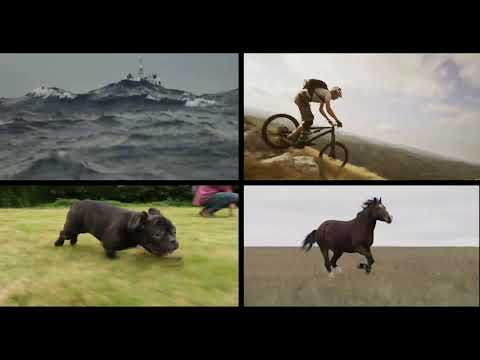

In [38]:
vid = YouTubeVideo(id='8I1RelnsgMw', width=800, height=600, allow_autoplay=True)
display(vid)
